# Three ways to split the same 97 blasts: random, deduplicated and whole campaigns held out

**Level 1: Fundamentals** · Needs: 01-the-data/01-the-corpus-and-the-cases · Reading time: about 20 minutes

## Objectives

A prediction is worth what it scores on blasts the model has not seen, and which blasts count as unseen depends on how the data are split. This notebook builds the three splits the product uses on the same 97 blasts and measures what each one lets through.

By the end you will have:

- drawn a random 80/20 split, the protocol the literature reports, and counted the test blasts that share their inputs with a training blast;
- found the duplicated input vectors of the corpus and drawn a split that collapses them first;
- built the ten leave-one-site-out splits and watched the leakage check refuse a split that puts a campaign on both sides.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 blasts | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The committed duplicate groups and site counts | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/benchmark.json`, fields `duplicate_groups` and `site_counts` |

The random 80/20 protocol is the one the learned-predictor studies report (Sui et al. 2025, https://doi.org/10.3390/app15031254).

## Method

A split is a `Split`: a training tuple, a test tuple, a protocol name and a note. Two properties decide whether it measures transfer.

1. **No row on both sides.** An identical blast in training and test is memorised, not predicted.
2. **No dependence across the cut.** Rows of one campaign share a rock mass, a rig, an explosive supply and a measurement operator, so a random split places near-copies of every test blast in training. Only holding the whole campaign out removes that, and it is also the question a practitioner asks: how well does this model transfer to my mine?

The engine builds the three splits and checks each one with `assert_no_leakage`, which raises a `LeakageError`. Cross-validation that ignores dependence in the data can seriously underestimate the prediction error (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

### Step 1: the random 80/20 split

`random_split` shuffles the rows with a seeded generator and cuts 20 percent off as the test set. The split carries a note that counts the test rows whose seven inputs are identical to a training row. The cell draws it, then draws 100 such splits with consecutive seeds to see how often the overlap occurs.

In [2]:
# Imports, then one random 80/20 split and the overlap it lets through
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
split = bf.random_split(train, seed=0)
print(split.protocol, "|", len(split.train), "training,", len(split.test), "test | seed", split.seed)
print("engine note:", split.note)
print("test rows with a twin in training:", split.detail["crossing_ids"])

# The same count over 100 consecutive seeds
crossing = [len(bf.random_split(train, seed=s).detail["crossing_ids"]) for s in range(100)]
print(f"draws with at least one twin: {sum(1 for c in crossing if c)} of 100 | mean twins per draw {np.mean(crossing):.2f} | max {max(crossing)}")

random-8020 | 78 training, 19 test | seed 0
engine note: 4 of 19 test rows share a feature vector with a training row
test rows with a twin in training: ['En12', 'En2', 'En3', 'Sm3']
draws with at least one twin: 96 of 100 | mean twins per draw 2.99 | max 6


### Step 2: where the twins come from

Some blasts of a campaign were fired with the same design, so their seven inputs are identical and only the measured size differs. `duplicate_groups` finds them. The cell lists the groups and checks them against the groups the bake committed.

In [3]:
# The groups of blasts that share one input vector, and the committed groups
groups = bf.duplicate_groups(train)
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
print("groups:", len(groups), "| rows involved:", sum(len(g) for g in groups))
by_id = {b.blast_id: b for b in train}
for group in groups:
    sizes = [by_id[i].x50_m for i in group]
    print(f"  {', '.join(group):<24} x50 (m): {sizes}")
print("same groups as the committed benchmark:", sorted(map(sorted, groups)) == sorted(map(sorted, benchmark["duplicate_groups"])))

groups: 7 | rows involved: 17
  En1, En2                 x50 (m): [0.37, 0.37]
  En11, En12               x50 (m): [0.31, 0.38]
  En3, En5                 x50 (m): [0.33, 0.46]
  En8, En9                 x50 (m): [0.42, 0.26]
  Mr1, Mr3                 x50 (m): [0.17, 0.13]
  Sm1, Sm2, Sm3            x50 (m): [0.15, 0.19, 0.23]
  Sm4, Sm5, Sm6, Sm7       x50 (m): [0.22, 0.24, 0.26, 0.28]
same groups as the committed benchmark: True


### Step 3: the deduplicated split

`deduplicated_split` first collapses each group to one representative whose measured size is the mean of the group, then splits. Averaging is a stated choice: duplicated inputs carry real measurement scatter (four Soma blasts share one input vector and have different sizes), and one row per distinct design is what a model should be asked to predict. The cell draws it and confirms no input vector crosses the cut.

In [4]:
# One deduplicated split and the check that no input vector crosses it
dedup = bf.deduplicated_split(train, seed=0)
print(dedup.protocol, "|", len(dedup.train), "training,", len(dedup.test), "test")
print("engine note:", dedup.note)
train_vectors = {b.features() for b in dedup.train}
print("test rows whose inputs are in training:", sum(1 for b in dedup.test if b.features() in train_vectors))

dedup-random | 70 training, 17 test
engine note: 97 rows collapsed to 87 distinct feature vectors before splitting
test rows whose inputs are in training: 0


### Step 4: leave one site out

`leave_one_site_out` yields one split per campaign: that campaign is the test set and the other nine are training. The cell lists the ten folds, then tries to build a split that is not valid (the whole corpus as training and Enusa as test) and shows `assert_no_leakage` refuse it.

In [5]:
# The ten folds, and a deliberately invalid split that the leakage check must refuse
folds = list(bf.leave_one_site_out(train))
print(f"{'held-out site':<18}{'test':>7}{'training':>14}")
for fold in folds:
    print(f"{fold.detail['held_out_site']:<18}{len(fold.test):>7}{len(fold.train):>14}")
print("sites in training of the first fold:", folds[0].detail["n_sites_in_train"])

enusa = tuple(b for b in train if b.site == "Enusa")
invalid = bf.Split(protocol="leave-out-Enusa", train=tuple(train), test=enusa, seed=None, note="", detail={})
try:
    bf.splits.assert_no_leakage(invalid, allow_duplicate_features=False)
except bf.LeakageError as refusal:
    print("refused:", str(refusal)[:90], "...")

held-out site        test      training
Akdaglar               22            75
Dongri-Buzurg           9            88
Enusa                  12            85
Miami                   6            91
Mrica                  11            86
Murgul                  7            90
Ozmert                  7            90
Reocin                 10            87
Reocin-UG               6            91
Soma                    7            90
sites in training of the first fold: 9
refused: leave-out-Enusa: 12 blast(s) on both sides: ['En1', 'En10', 'En11', 'En12', 'En2', 'En3',  ...


The last cell draws the three protocols on the same ten campaigns: for one random draw, the share of each campaign that falls in the test set, against the all-or-nothing of the site-held-out protocol.

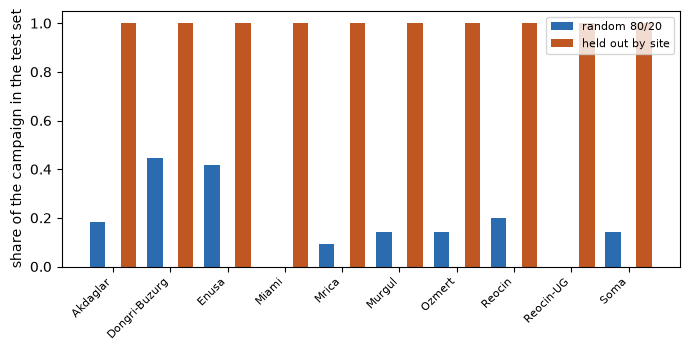

In [6]:
# Share of each campaign in the test set: one random draw, and held out by site
sites = sorted({b.site for b in train})
def share(rows, site):
    return sum(1 for b in rows if b.site == site) / sum(1 for b in train if b.site == site)

random_test = [share(split.test, s) for s in sites]
fig, ax = plt.subplots(figsize=(7, 3.6))
position = np.arange(len(sites))
ax.bar(position - 0.27, random_test, 0.27, label="random 80/20", color="#2b6cb0")
ax.bar(position + 0.27, [1.0] * len(sites), 0.27, label="held out by site", color="#c05621")
ax.set_xticks(position, sites, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("share of the campaign in the test set")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

**A random split leaks, and the engine says so.** In the first draw 4 of the 19 test blasts have an identical input vector in training, and over 100 draws almost every draw carries at least one twin. A model that memorises the training rows scores well on such a split without having learned anything that transfers.

**The twins are real, few and local.** Seven groups of blasts share an input vector, 17 rows in all, within the Enusa, Mrica and Soma campaigns, and the groups equal the ones the bake committed. Collapsing them removes the shared vectors (ten rows fewer) and the split then has no input vector across the cut, but it does not remove the dependence between blasts of the same campaign.

**Only holding a campaign out removes the dependence.** The ten folds put 6 to 22 blasts in the test set and the remaining sites in training. The engine refuses a split that puts a campaign on both sides, so the protocol cannot be run wrongly by accident.

**What this does not show.** The splits say what is held out, not how any model scores on it. The next notebook defines the scores. With ten campaigns, the held-out score of any model also rests on ten test sets of very different sizes, one of them a quarter of the corpus.

## Summary

- Three splits of the same rows: random 80/20 (leaks), deduplicated (no shared input vector), and one whole campaign held out per fold (no dependence across the cut).
- The engine counts the leak in the random split and refuses an invalid leave-one-site-out split.
- Next: notebook 02 defines the score, the null model and the interval, and applies the product's pre-declared criterion.

## References

- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (cross-validation under dependent data)
- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (the random 80/20 protocol of the learned-predictor studies)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/